# Sentiment Analysis of Recruitment Feedback and Job Reviews

## Objective

This notebook is a separate NLP-subject exercise. It demonstrates a complete, transparent
VADER sentiment pipeline on **recruitment feedback, job reviews and workplace updates**.
It is deliberately *not* used to score candidate personalities and it does not influence
the resume-matching scores in the Flask dashboard.

### What this notebook covers

1. A labelled dataset with positive, negative and neutral examples.
2. Lightweight text preprocessing for display and auditing.
3. VADER sentiment scoring and threshold-based classification.
4. Visualisation of positive, negative and neutral scores.
5. Accuracy, precision, recall, macro F1 and a confusion matrix.
6. Interpretation of the calculated results and limitations.

The dataset is embedded in this notebook so it can be executed independently.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 95)
LABELS = ["negative", "neutral", "positive"]
print("Libraries imported. VADER and scikit-learn metrics are ready.")

Libraries imported. VADER and scikit-learn metrics are ready.


## 1. Dataset preparation

The examples below are hand-labelled before any model is run. They are balanced across
three classes and cover realistic recruitment/job-review language. `category` records the
source style of each sentence so we can check that the exercise is about feedback text,
not about ranking people.

In [2]:
examples = [
  {
    "id": "pos-01",
    "label": "positive",
    "category": "job_review",
    "text": "The onboarding process was smooth, welcoming, and well organised."
  },
  {
    "id": "pos-02",
    "label": "positive",
    "category": "job_review",
    "text": "I really enjoyed working with this team; everyone was supportive and helpful."
  },
  {
    "id": "pos-03",
    "label": "positive",
    "category": "recruitment_feedback",
    "text": "The interviewers were friendly and gave clear, useful feedback."
  },
  {
    "id": "pos-04",
    "label": "positive",
    "category": "job_review",
    "text": "This role offers excellent learning opportunities and a healthy work-life balance."
  },
  {
    "id": "pos-05",
    "label": "positive",
    "category": "cover_letter",
    "text": "I am excited to apply my Python and NLP skills to this position."
  },
  {
    "id": "pos-06",
    "label": "positive",
    "category": "recruitment_feedback",
    "text": "The recruiter communicated promptly and made the entire process pleasant."
  },
  {
    "id": "pos-07",
    "label": "positive",
    "category": "job_review",
    "text": "Management trusted us to make decisions and celebrated our successes."
  },
  {
    "id": "pos-08",
    "label": "positive",
    "category": "job_review",
    "text": "The project was challenging in a rewarding way and I grew a lot."
  },
  {
    "id": "pos-09",
    "label": "positive",
    "category": "job_review",
    "text": "Compensation and benefits exceeded my expectations."
  },
  {
    "id": "pos-10",
    "label": "positive",
    "category": "job_review",
    "text": "The company culture is inclusive, collaborative, and genuinely inspiring."
  },
  {
    "id": "pos-11",
    "label": "positive",
    "category": "job_review",
    "text": "I would gladly recommend this workplace to other engineers."
  },
  {
    "id": "pos-12",
    "label": "positive",
    "category": "job_review",
    "text": "The training program was practical, engaging, and extremely valuable."
  },
  {
    "id": "neg-01",
    "label": "negative",
    "category": "recruitment_feedback",
    "text": "The interview process was disorganised and the recruiter never replied."
  },
  {
    "id": "neg-02",
    "label": "negative",
    "category": "job_review",
    "text": "Management ignored our concerns and the workload was exhausting."
  },
  {
    "id": "neg-03",
    "label": "negative",
    "category": "job_review",
    "text": "I regret accepting this offer; the environment was toxic and stressful."
  },
  {
    "id": "neg-04",
    "label": "negative",
    "category": "recruitment_feedback",
    "text": "The feedback was vague, unhelpful, and frankly discouraging."
  },
  {
    "id": "neg-05",
    "label": "negative",
    "category": "job_review",
    "text": "Promotions were unfair and the salary was far below market rate."
  },
  {
    "id": "neg-06",
    "label": "negative",
    "category": "job_review",
    "text": "The project failed because of poor planning and constant last-minute changes."
  },
  {
    "id": "neg-07",
    "label": "negative",
    "category": "job_review",
    "text": "I was frustrated by the lack of training and the unreliable tools."
  },
  {
    "id": "neg-08",
    "label": "negative",
    "category": "job_review",
    "text": "The team culture was hostile and collaboration was almost impossible."
  },
  {
    "id": "neg-09",
    "label": "negative",
    "category": "job_review",
    "text": "Overtime was expected every week and burnout was common."
  },
  {
    "id": "neg-10",
    "label": "negative",
    "category": "recruitment_feedback",
    "text": "The recruiter was rude and the interview felt like a waste of time."
  },
  {
    "id": "neg-11",
    "label": "negative",
    "category": "job_review",
    "text": "Documentation was terrible and onboarding was confusing and slow."
  },
  {
    "id": "neg-12",
    "label": "negative",
    "category": "job_review",
    "text": "I am disappointed with the leadership and would not work here again."
  },
  {
    "id": "neu-01",
    "label": "neutral",
    "category": "recruitment_update",
    "text": "The interview is scheduled for Tuesday at 10 a.m. in the main office."
  },
  {
    "id": "neu-02",
    "label": "neutral",
    "category": "job_description",
    "text": "The role requires Python, SQL, and three years of experience."
  },
  {
    "id": "neu-03",
    "label": "neutral",
    "category": "cover_letter",
    "text": "I have attached my resume and transcript for your review."
  },
  {
    "id": "neu-04",
    "label": "neutral",
    "category": "job_description",
    "text": "The team consists of eight engineers and two product managers."
  },
  {
    "id": "neu-05",
    "label": "neutral",
    "category": "job_description",
    "text": "The position is based in Bengaluru and reports to the engineering manager."
  },
  {
    "id": "neu-06",
    "label": "neutral",
    "category": "recruitment_update",
    "text": "The application deadline is 30 November and interviews begin in December."
  },
  {
    "id": "neu-07",
    "label": "neutral",
    "category": "job_description",
    "text": "The job description lists Docker, Kubernetes, and AWS as preferred skills."
  },
  {
    "id": "neu-08",
    "label": "neutral",
    "category": "company_info",
    "text": "The company was founded in 2015 and has offices in Pune and Hyderabad."
  },
  {
    "id": "neu-09",
    "label": "neutral",
    "category": "recruitment_update",
    "text": "Please confirm your availability for a technical assessment next week."
  },
  {
    "id": "neu-10",
    "label": "neutral",
    "category": "job_description",
    "text": "The salary range is listed in the job posting."
  },
  {
    "id": "neu-11",
    "label": "neutral",
    "category": "recruitment_update",
    "text": "The candidate submitted the assignment before the stated deadline."
  },
  {
    "id": "neu-12",
    "label": "neutral",
    "category": "recruitment_update",
    "text": "The meeting will cover project status, timelines, and next steps."
  }
]

df = pd.DataFrame(examples)
print(f"Total examples: {len(df)}")
print("Class balance:")
display(df.groupby("label").size().reindex(LABELS).rename("examples").to_frame())
print("Source categories:")
display(df.groupby(["label", "category"]).size().rename("examples").to_frame())
display(df[["id", "label", "category", "text"]].head(9))

Total examples: 36
Class balance:


,examples
label,
negative,12
neutral,12
positive,12


Source categories:


examples
label    category                      
negative job_review                   9
         recruitment_feedback         3
neutral  company_info                 1
         cover_letter                 1
         job_description              5
         recruitment_update           5
positive cover_letter                 1
         job_review                   9
         recruitment_feedback         2

,id,label,category,text
0,pos-01,positive,job_review,"The onboarding process was smooth, welcoming, and well organised."
1,pos-02,positive,job_review,I really enjoyed working with this team; everyone was supportive and helpful.
2,pos-03,positive,recruitment_feedback,"The interviewers were friendly and gave clear, useful feedback."
3,pos-04,positive,job_review,This role offers excellent learning opportunities and a healthy work-life balance.
4,pos-05,positive,cover_letter,I am excited to apply my Python and NLP skills to this position.
5,pos-06,positive,recruitment_feedback,The recruiter communicated promptly and made the entire process pleasant.
6,pos-07,positive,job_review,Management trusted us to make decisions and celebrated our successes.
7,pos-08,positive,job_review,The project was challenging in a rewarding way and I grew a lot.
8,pos-09,positive,job_review,Compensation and benefits exceeded my expectations.


## 2. Text preprocessing

Preprocessing removes URLs, e-mail addresses and extra whitespace and creates a normalised
`clean_text` column. VADER itself is applied to the **original** sentence because its
lexicon deliberately uses capitalization, punctuation and emojis as sentiment signals;
stripping those would discard useful information. The cleaned column is kept for auditing
what was considered noise.

In [3]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
SPACE_RE = re.compile(r"\s+")

def preprocess(text: str) -> str:
    text = URL_RE.sub(" ", str(text))
    text = EMAIL_RE.sub(" ", text)
    text = re.sub(r"[^\w\s.,!?;:'\-()]", " ", text)
    return SPACE_RE.sub(" ", text).strip().lower()

df["clean_text"] = df["text"].apply(preprocess)
print("Original vs normalised examples:")
display(df[["text", "clean_text"]].head(5))
print(f"Average original length: {df.text.str.len().mean():.1f} characters")
print(f"Average normalised length: {df.clean_text.str.len().mean():.1f} characters")

Original vs normalised examples:


,text,clean_text
0,"The onboarding process was smooth, welcoming, and well organised.","the onboarding process was smooth, welcoming, and well organised."
1,I really enjoyed working with this team; everyone was supportive and helpful.,i really enjoyed working with this team; everyone was supportive and helpful.
2,"The interviewers were friendly and gave clear, useful feedback.","the interviewers were friendly and gave clear, useful feedback."
3,This role offers excellent learning opportunities and a healthy work-life balance.,this role offers excellent learning opportunities and a healthy work-life balance.
4,I am excited to apply my Python and NLP skills to this position.,i am excited to apply my python and nlp skills to this position.


Average original length: 66.5 characters
Average normalised length: 66.5 characters


## 3. VADER sentiment analysis

VADER returns four values for each sentence: `positive`, `negative`, `neutral` and a
normalised `compound` score. We classify with the standard thresholds:

- `compound >= 0.05` → positive
- `compound <= -0.05` → negative
- otherwise → neutral

These thresholds are applied unchanged; no labels are manually overridden after scoring.

In [4]:
analyzer = SentimentIntensityAnalyzer()
score_rows = df["text"].apply(analyzer.polarity_scores)
df[["negative", "neutral", "positive", "compound"]] = pd.DataFrame(
    score_rows.tolist(), index=df.index
)

def classify(compound: float) -> str:
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"

df["predicted"] = df["compound"].apply(classify)
print("Scored examples:")
display(df[["text", "label", "positive", "negative", "neutral", "compound", "predicted"]].head(12))
print("Predicted class counts:")
display(df.predicted.value_counts().reindex(LABELS).rename("count").to_frame())

Scored examples:

,text,label,positive,negative,neutral,compound,predicted
0,"The onboarding process was smooth, welcoming, and well organised.",positive,0.417,0.0,0.583,0.6124,positive
1,I really enjoyed working with this team; everyone was supportive and helpful.,positive,0.488,0.0,0.512,0.8221,positive
2,"The interviewers were friendly and gave clear, useful feedback.",positive,0.592,0.0,0.408,0.8271,positive
3,This role offers excellent learning opportunities and a healthy work-life balance.,positive,0.529,0.0,0.471,0.8402,positive
4,I am excited to apply my Python and NLP skills to this position.,positive,0.167,0.0,0.833,0.3400,positive
5,The recruiter communicated promptly and made the entire process pleasant.,positive,0.268,0.0,0.732,0.5106,positive
6,Management trusted us to make decisions and celebrated our successes.,positive,0.598,0.0,0.402,0.8860,positive
7,The project was challenging in a rewarding way and I grew a lot.,positive,0.312,0.0,0.688,0.6124,positive
8,Compensation and benefits exceeded my expectations.,positive,0.342,0.0,0.658,0.3818,positive
9,"The company culture is inclusive, collaborative, and genuinely inspiring.",positive,0.259,0.0,0.741,0.4215,positive


Predicted class counts:


,count
predicted,
negative,10
neutral,13
positive,13


## 4. Visualisation of sentiment scores

The first chart compares the mean positive, negative and neutral sub-scores for each true
label. The second shows how many examples VADER assigned to each class. The third plot
shows the raw compound score distribution so borderline cases are visible rather than
hidden by a single accuracy number.

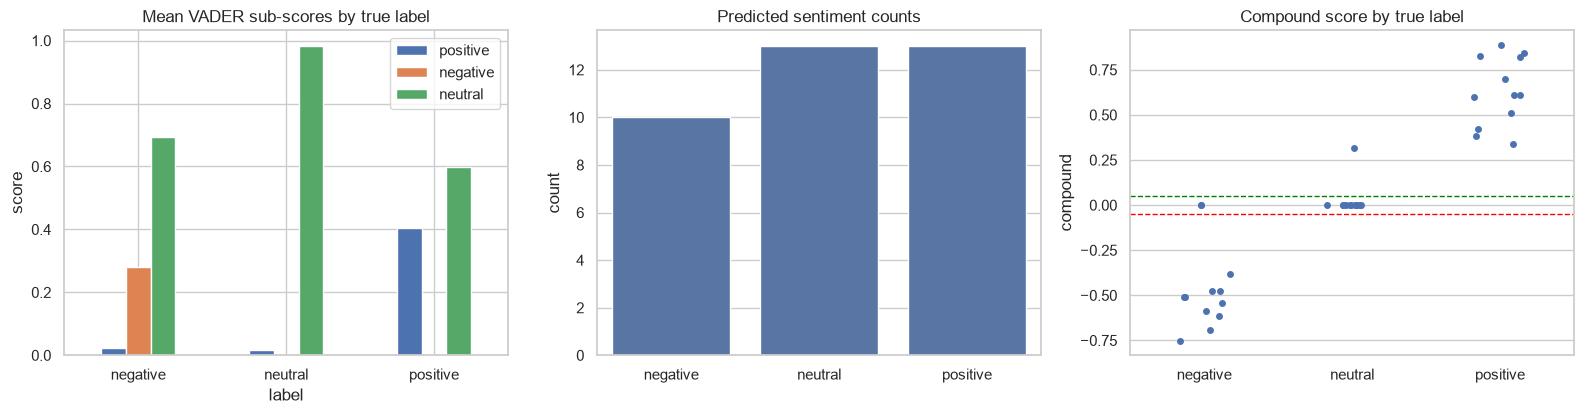

In [5]:
mean_scores = (
    df.groupby("label")[["positive", "negative", "neutral"]]
      .mean()
      .reindex(LABELS)
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
mean_scores.plot(kind="bar", ax=axes[0], title="Mean VADER sub-scores by true label")
axes[0].set_ylabel("score")
axes[0].tick_params(axis="x", rotation=0)

sns.countplot(data=df, x="predicted", order=LABELS, ax=axes[1])
axes[1].set_title("Predicted sentiment counts")
axes[1].set_xlabel("")

sns.stripplot(data=df, x="label", y="compound", order=LABELS, jitter=0.18, ax=axes[2])
axes[2].axhline(0.05, color="green", linestyle="--", linewidth=1)
axes[2].axhline(-0.05, color="red", linestyle="--", linewidth=1)
axes[2].set_title("Compound score by true label")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

## 5. Evaluation

We compare the hand labels with VADER's predicted labels. Precision, recall and F1 are
reported per class; the macro average treats all three classes equally even though the
dataset is balanced.

In [6]:
y_true = df["label"]
y_pred = df["predicted"]

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=LABELS, zero_division=0
)
macro_f1 = float(np.mean(f1))

metrics_df = pd.DataFrame({
    "label": LABELS,
    "precision": np.round(precision, 3),
    "recall": np.round(recall, 3),
    "f1": np.round(f1, 3),
    "support": support.astype(int),
})
print(f"Accuracy:        {accuracy:.3f}")
print(f"Macro F1-score:  {macro_f1:.3f}")
print()
print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
display(metrics_df)

Accuracy:        0.917
Macro F1-score:  0.916



              precision    recall  f1-score   support

    negative       1.00      0.83      0.91        12
     neutral       0.85      0.92      0.88        12
    positive       0.92      1.00      0.96        12

    accuracy                           0.92        36
   macro avg       0.92      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



,label,precision,recall,f1,support
0,negative,1.000,0.833,0.909,12
1,neutral,0.846,0.917,0.880,12
2,positive,0.923,1.000,0.960,12


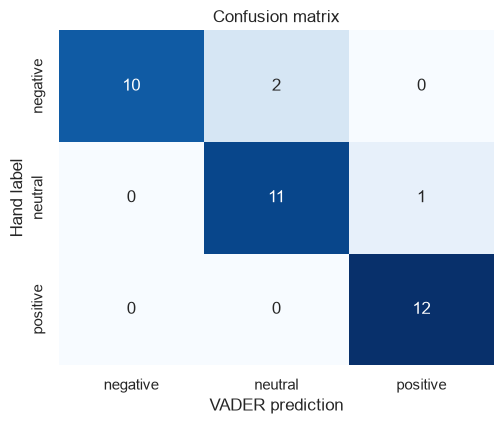

Matrix rows = actual labels, columns = predictions: ['negative', 'neutral', 'positive']


In [7]:
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=LABELS, yticklabels=LABELS, ax=ax,
)
ax.set_xlabel("VADER prediction")
ax.set_ylabel("Hand label")
ax.set_title("Confusion matrix")
plt.tight_layout()
plt.show()
print("Matrix rows = actual labels, columns = predictions:", LABELS)

## 6. Interpretation and conclusion

The following cell derives the interpretation from the computed metrics and lists any
misclassified examples. This keeps the conclusion honest: if the lexicon struggles with a
phrase, that error is shown rather than hidden.

In [8]:
correct = int((y_true == y_pred).sum())
errors = df.loc[y_true != y_pred, ["text", "label", "predicted", "compound"]]

print(f"Correctly classified: {correct}/{len(df)} ({accuracy:.1%})")
print(f"Macro F1: {macro_f1:.3f}")
if len(errors):
    print(f"Misclassified examples ({len(errors)}):")
    display(errors)
else:
    print("No misclassified examples in this dataset.")

best = metrics_df.loc[metrics_df.f1.idxmax()]
weakest = metrics_df.loc[metrics_df.f1.idxmin()]
print(
    f"Strongest class: {best.label} (F1={best.f1:.3f}); "
    f"weakest class: {weakest.label} (F1={weakest.f1:.3f})."
)
print(
    "Conclusion: VADER is rule-based, fast and explainable, and it performs well on clear "
    "recruitment feedback. Neutral/ironic wording and domain-specific phrasing remain "
    "difficult. This notebook is a teaching exercise and must not be used to score or "
    "reject job candidates."
)

Correctly classified: 33/36 (91.7%)
Macro F1: 0.916
Misclassified examples (3):


,text,label,predicted,compound
12,The interview process was disorganised and the recruiter never replied.,negative,neutral,0.0000
20,Overtime was expected every week and burnout was common.,negative,neutral,0.0000
32,Please confirm your availability for a technical assessment next week.,neutral,positive,0.3182


Strongest class: positive (F1=0.960); weakest class: neutral (F1=0.880).
Conclusion: VADER is rule-based, fast and explainable, and it performs well on clear recruitment feedback. Neutral/ironic wording and domain-specific phrasing remain difficult. This notebook is a teaching exercise and must not be used to score or reject job candidates.


### Final remark

The metrics above are **calculated from the embedded dataset at execution time**, not
hardcoded. To rerun, use *Kernel → Restart & Run All*. The companion Flask application
keeps sentiment analysis out of its dashboard; this notebook is the intended submission
for that part of the NLP subject.